All The Imports

In [5]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import random
import requests
import numpy as np
from PIL import Image
import base64
from io import BytesIO

import torch
import torchvision.transforms.functional as F
from diffusers import StableDiffusionPipeline, ControlNetModel, StableDiffusionControlNetPipeline

c:\ProgramData\Anaconda3\envs\RVC\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\ProgramData\Anaconda3\envs\RVC\lib\site-packages\transformers\utils\generic.py:260: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(
c:\ProgramData\Anaconda3\envs\RVC\lib\site-packages\transformers\utils\generic.py:260: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(


# **Text to Image**

In [23]:
repo = "Models\sdxs-512-dreamshaper"

seed = 42
weight_type = torch.float32     # or float16

# Load model.
pipe = StableDiffusionPipeline.from_pretrained(repo, torch_dtype=weight_type)

# use original VAE
# pipe.vae = AutoencoderKL.from_pretrained("IDKiro/sdxs-512-0.9/vae_large")

pipe.to("cuda")


Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00,  9.65it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


StableDiffusionPipeline {
  "_class_name": "StableDiffusionPipeline",
  "_diffusers_version": "0.30.2",
  "_name_or_path": "Models\\sdxs-512-dreamshaper",
  "feature_extractor": [
    "transformers",
    "CLIPFeatureExtractor"
  ],
  "image_encoder": [
    null,
    null
  ],
  "requires_safety_checker": true,
  "safety_checker": [
    null,
    null
  ],
  "scheduler": [
    "diffusers",
    "DEISMultistepScheduler"
  ],
  "text_encoder": [
    "transformers",
    "CLIPTextModel"
  ],
  "tokenizer": [
    "transformers",
    "CLIPTokenizer"
  ],
  "unet": [
    "diffusers",
    "UNet2DConditionModel"
  ],
  "vae": [
    "diffusers",
    "AutoencoderTiny"
  ]
}

In [24]:
PROMPT = "portrait photo of a cat"

# Ensure using 1 inference step and CFG set to 0.
image = pipe(
    PROMPT,
    num_inference_steps=1,
    guidance_scale=0,
    generator=torch.Generator(device="cuda").manual_seed(seed)
).images[0]

image.save("Outputs/t2ioutput.png")


100%|██████████| 1/1 [00:00<00:00,  4.48it/s]


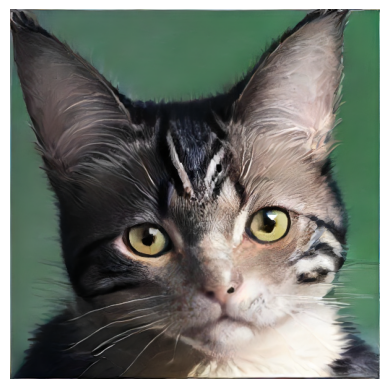

In [25]:
img = mpimg.imread("Outputs/t2ioutput.png")
plt.imshow(img)
plt.axis('off')
plt.show()

# **Image to Image**


In [6]:
device = "cuda"   # Linux & Windows
weight_type = torch.float32  # torch.float16 works as well, but pictures seem to be a bit worse

controlnet = ControlNetModel.from_pretrained(
    "Models\sdxs-512-dreamshaper-sketch", torch_dtype=weight_type
).to(device)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "Models\sdxs-512-dreamshaper", controlnet=controlnet, torch_dtype=weight_type
)
pipe.to(device)

An error occurred while trying to fetch Models\sdxs-512-dreamshaper-sketch: Error no file named diffusion_pytorch_model.safetensors found in directory Models\sdxs-512-dreamshaper-sketch.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
Loading pipeline components...:  50%|█████     | 3/6 [00:00<00:00,  4.35it/s]c:\ProgramData\Anaconda3\envs\RVC\lib\site-packages\transformers\models\clip\feature_extraction_clip.py:28: FutureWarning: The class CLIPFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use CLIPImageProcessor instead.
  warnings.warn(
Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00,  6.55it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or a

StableDiffusionControlNetPipeline {
  "_class_name": "StableDiffusionControlNetPipeline",
  "_diffusers_version": "0.30.2",
  "_name_or_path": "Models\\sdxs-512-dreamshaper",
  "controlnet": [
    "diffusers",
    "ControlNetModel"
  ],
  "feature_extractor": [
    "transformers",
    "CLIPFeatureExtractor"
  ],
  "image_encoder": [
    null,
    null
  ],
  "requires_safety_checker": true,
  "safety_checker": [
    null,
    null
  ],
  "scheduler": [
    "diffusers",
    "DEISMultistepScheduler"
  ],
  "text_encoder": [
    "transformers",
    "CLIPTextModel"
  ],
  "tokenizer": [
    "transformers",
    "CLIPTokenizer"
  ],
  "unet": [
    "diffusers",
    "UNet2DConditionModel"
  ],
  "vae": [
    "diffusers",
    "AutoencoderTiny"
  ]
}

In [7]:
style_list = [
    {
        "name": "No Style",
        "prompt": "{prompt}",
    },
    {
        "name": "Manga",
        "prompt": "manga style {prompt} . vibrant, high-energy, detailed, iconic, Japanese comic style",
    },
]

In [8]:
DEFAULT_STYLE_NAME = "No Style"

In [9]:
styles = {k["name"]: k["prompt"] for k in style_list}
STYLE_NAMES = list(styles.keys())
MAX_SEED = np.iinfo(np.int32).max

In [10]:
styles[DEFAULT_STYLE_NAME]

'{prompt}'

Utility

In [11]:
def pil_image_to_data_url(img, format="PNG"):
    buffered = BytesIO()
    img.save(buffered, format=format)
    img_str = base64.b64encode(buffered.getvalue()).decode()
    return f"data:image/{format.lower()};base64,{img_str}"


def randomize_seed_fn(seed: int, randomize_seed: bool) -> int:
    if randomize_seed:
        seed = random.randint(0, MAX_SEED)
    return seed

Test Image

In [12]:
# RYAN_BLACK&WHITE = https://i.ibb.co/GWxJyxJ/Ryan-Reynolds-ezgif-com-webp-to-jpg-converter.jpg
# RYAN_COLOR = https://i.ibb.co/Bw9QrHR/ryan-color.jpg

In [13]:
#URL = 'https://i.ibb.co/Bw9QrHR/ryan-color.jpg' # @param {type:"string"}

In [14]:
#img_request = requests.get(URL)
#image = Image.open(BytesIO(img_request.content))

In [15]:
import cv2

img = cv2.imread("dark_skin.jpg")
# You may need to convert the color.
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
image = Image.fromarray(img)

# For reversing the operation:
#im_np = np.asarray(im_pil)

In [16]:
def run(
    image,
    prompt,
    prompt_template,
    style_name,
    controlnet_conditioning_scale,
    device_type="GPU",
    param_dtype='torch.float16',
):
    if device_type == "CPU":
        device = "cpu"
        param_dtype = 'torch.float32'
    else:
        device = "cuda"

    pipe.to(torch_device=device, torch_dtype=torch.float16 if param_dtype == 'torch.float16' else torch.float32)

    print(f"prompt: {prompt}")

    if image is None:
        print("Image Not Loaded!")

    prompt = prompt_template.replace("{prompt}", prompt)
    control_image = image.convert("RGB")
    control_image = Image.fromarray(255 - np.array(control_image))

    output_pil = pipe(
        prompt=prompt,
        image=control_image,
        width=512,
        height=512,
        guidance_scale=1,
        num_inference_steps=1,
        num_images_per_prompt=1,
        output_type="pil",
        controlnet_conditioning_scale=controlnet_conditioning_scale,
    ).images[0]

    return (
        output_pil

    )

style = "Manga"
prompt_temp = "manga style {prompt} . vibrant, high-energy, detailed, iconic, Japanese comic style"

controlnet_conditioning_scale = 1.8

device_choices = ['GPU','CPU']
dtype_choices = ['torch.float16','torch.float32']

device_type = 'GPU'
param_dtype = 'torch.float32'

prompt = "Potrait face of a man"

inputs = [image, prompt, prompt_temp, style, controlnet_conditioning_scale, device_type, param_dtype]


output = run(image, prompt, prompt_temp, style, controlnet_conditioning_scale, device_type, param_dtype)

output.save("Outputs/i2ioutput.png")

prompt: Potrait face of a man


  0%|          | 0/1 [00:00<?, ?it/s]c:\ProgramData\Anaconda3\envs\RVC\lib\site-packages\diffusers\models\attention_processor.py:2358: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:555.)
  hidden_states = F.scaled_dot_product_attention(
100%|██████████| 1/1 [00:00<00:00,  1.42it/s]


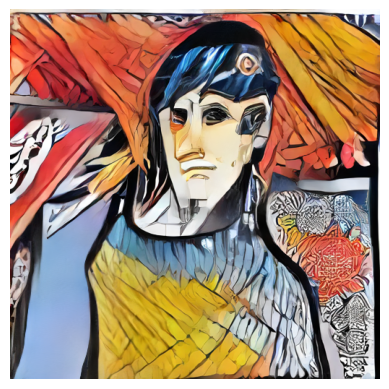

In [17]:
img = mpimg.imread("Outputs/i2ioutput.png")
plt.imshow(img)
plt.axis('off')
plt.show()

WebCam

In [22]:
import cv2
import time

# DroidCam = 0
# Initialize the camera
cam = cv2.VideoCapture(0)

frame_rate = 30
fps = 0
# Start an infinite loop for real-time image processing
# Default FPS of my WebCam is 30

i = 310

while True:
    # Read a frame from the camera
    status, photo = cam.read()
    
    #i = i + 1
    
    # Perform image manipulation: cropping and copying
    #photo[0:200, 0:150] = photo[100:300, 150:300]

    photo = cv2.resize(photo, (1024, 1024))

    img = cv2.cvtColor(photo, cv2.COLOR_BGR2RGB)
    photo = Image.fromarray(img)
    
    
    start_time = time.time()
    
    if (i < 80):
        prompt_temp = "manga style {prompt} . vibrant, high-energy, detailed, iconic, Japanese comic style"
        controlnet_conditioning_scale = 0.5
        prompt = "Portrait of a man"
    elif (i < 160):
        prompt_temp = "neonpunk style {prompt} . cyberpunk, vaporwave, neon, vibes, vibrant, stunningly beautiful, crisp, detailed, sleek, ultramodern, magenta highlights, dark purple shadows, high contrast, cinematic, ultra detailed, intricate, professional"   
        controlnet_conditioning_scale = 1.8
        prompt = "Portrait of a man"
    elif (i < 240):
        prompt_temp = "pixel-art {prompt} . low-res, blocky, pixel art style, 8-bit graphics"   
        controlnet_conditioning_scale = 1.8
        prompt = "Portrait of a man"
    elif (i < 320):
        prompt_temp = "anime artwork {prompt} . anime style, key visual, vibrant, studio anime,  highly detailed"    
        controlnet_conditioning_scale = 2.8
        prompt = "animals"
    elif (i < 400):
        prompt_temp = "cinematic still {prompt} . emotional, harmonious, vignette, highly detailed, high budget, bokeh, cinemascope, moody, epic, gorgeous, film grain, grainy"   
        controlnet_conditioning_scale = 2.2
        prompt = ""
    elif (i < 480):
        prompt_temp = "cinematic photo {prompt} . 35mm photograph, film, bokeh, professional, 4k, highly detailed"
        controlnet_conditioning_scale = 2.2
        prompt = ""

    #controlnet_conditioning_scale = 1.8
    output = run(photo, prompt, prompt_temp, style, controlnet_conditioning_scale, device_type, param_dtype)

    opencvImage = cv2.cvtColor(np.array(output), cv2.COLOR_RGB2BGR)


    ###

    

    # Calculate FPS if loopTime is non-zero
    loopTime2 = time.time() - start_time

    if loopTime2 > 0:
        fps = 0.9*fps+.1 / loopTime2
        print("FPS:", fps)
    
    opencvImage = cv2.resize(opencvImage, (1024, 1024))

    # Display FPS on the frame
    cv2.putText(opencvImage, f"FPS: {fps}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 200, 0), 2, cv2.LINE_AA)
    cv2.putText(opencvImage, f"PROMPT: {prompt_temp}", (10, 70), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2, cv2.LINE_AA)

    # Display the modified image
    cv2.imshow("myphoto", opencvImage)
    
    # Check for the 'Enter' key press to exit the loop
    if cv2.waitKey(10) == 13:
        break

# Release the camera and close all windows
cv2.destroyAllWindows()
cam.release()

prompt: animals


100%|██████████| 1/1 [00:00<00:00, 11.13it/s]

FPS: 0.49049073584649716


prompt: animals


100%|██████████| 1/1 [00:00<00:00, 11.12it/s]


FPS: 0.893711365407234
prompt: animals


... (158 outputs left out)

100%|██████████| 1/1 [00:00<00:00, 10.71it/s]


FPS: 4.9019573423418095
prompt: animals


100%|██████████| 1/1 [00:00<00:00, 11.14it/s]

FPS: 4.935657995558009
